# Dataset and Compositional OOD Protocol

**Question.** Can a DDPM trained from scratch combine attribute values whose *pair* was withheld, while each primitive remains observed in TRAIN?  This notebook is CPU-only and reads aggregate, frozen protocol records only.

In [24]:
from pathlib import Path
import json
ROOT = Path.cwd().resolve()
while not (ROOT / 'data').exists() and ROOT.parent != ROOT: ROOT = ROOT.parent
split = json.loads((ROOT/'data/processed/dr01_v1/split_summary.json').read_text())
mapping = json.loads((ROOT/'data/processed/dr01_v1/semantic_mapping.json').read_text())
print('Repository:', ROOT)
print(json.dumps(split, indent=2)[:4000])

Repository: C:\Users\Bartolo\Desktop\PROGETTI\DL_Project
{
  "schema": "tiny_avatar_diffusion.dr01_split_summary",
  "version": "dr01_v1",
  "generation_timestamp_utc": "2026-09-28T15:59:40.456059+00:00",
  "cross_dataset_consistency": {
    "selected_attributes_identical": true,
    "heldout_definitions_identical": true,
    "precedence_identical": true,
    "id_split_policy_identical": true,
    "split_seed_identical": true,
    "all_checks_passed": true
  },
  "datasets": {
    "10k": {
      "source_count": 10000,
      "role_counts_before_id_split": {
        "FINAL_OOD": 342,
        "COMP_VAL": 338,
        "ID_POOL": 9320
      },
      "pair_counts_before_precedence": {
        "CV1": 68,
        "CV2": 147,
        "CV3": 54,
        "CV4": 82,
        "OOD1": 72,
        "OOD2": 137,
        "OOD3": 47,
        "OOD4": 86
      },
      "pair_counts_after_precedence": {
        "CV1": 66,
        "CV2": 139,
        "CV3": 52,
        "CV4": 82,
        "OOD1": 72,
        "

## Provenance and split logic

The tokenizer and prompt grammar are derived from TRAIN only.  ID validation measures interpolation over known combinations; compositional OOD holds out four documented attribute-value pairs.  Record-level protected manifests are intentionally not loaded here.

In [25]:
attrs = mapping['attributes'] if 'attributes' in mapping else mapping
names = list(attrs)
counts = [len(attrs[k]) if isinstance(attrs[k], list) else len(attrs[k]) for k in names]
print(dict(zip(names, counts)))

{'face_shape': 7, 'glasses': 12, 'hair_color': 10, 'face_color': 11}


## Interpretation and limits

OOD means an unseen *composition*, not unseen lexical tokens or classes.  It is therefore a controlled generalization question, not open-vocabulary generation.  See `reports/dr01_final_split/final_split_report.md` and `reports/dr01_semantic_mapping/semantic_mapping_audit.md` for the frozen provenance.

## 1. Attributes, deterministic captions, and the train-only tokenizer

Each image has four selected semantic attributes: `face_shape`, `glasses`, `hair_color`, and `face_color`. The canonical caption orders them deterministically after the `avatar` prefix. The vocabulary is built from **TRAIN captions only**; it is not fitted on validation or OOD text. This cell reads one frozen TRAIN record, regenerates its caption through the public caption function, and checks its stored tokenisation.

In [26]:
from pathlib import Path
import json
from IPython.display import Markdown, display
from tiny_avatar_diffusion.captions import generate_caption
from tiny_avatar_diffusion.tokenizer import WhitespaceTokenizer

DATA = ROOT / 'data' / 'processed' / 'dr01_v1'
VARIANT = '10k'
train_path = DATA / 'text' / VARIANT / 'train.jsonl'
example = json.loads(train_path.read_text(encoding='utf-8').splitlines()[0])
vocab_payload = json.loads((DATA / 'text' / VARIANT / 'vocab.json').read_text(encoding='utf-8'))
token_to_id = vocab_payload.get('token_to_id', vocab_payload)
tokenizer = WhitespaceTokenizer(token_to_id)
attributes = {name: example[name] for name in ('face_shape', 'glasses', 'hair_color', 'face_color')}
caption = generate_caption(attributes)
encoded = tokenizer.encode(caption)
assert caption == example['caption']
assert encoded.token_ids == example['token_ids']
assert len(encoded.token_ids) == 7  # BOS + 5 lexical tokens + EOS

display(Markdown(
    f"**Frozen TRAIN example**  \\n"
    f"`image_id`: `{example['image_id']}`  \\n"
    f"attributes: `{attributes}`  \\n"
    f"caption: `{caption}`  \\n"
    f"tokens: `{example['tokens']}`  \\n"
    f"token IDs: `{encoded.token_ids}`"
))


**Frozen TRAIN example**  \n`image_id`: `cs10000053986926948907`  \nattributes: `{'face_shape': 4, 'glasses': 0, 'hair_color': 9, 'face_color': 10}`  \ncaption: `avatar face_shape_round glasses_oversized_glasses hair_color_silver face_color_pale_pink`  \ntokens: `['<bos>', 'avatar', 'face_shape_round', 'glasses_oversized_glasses', 'hair_color_silver', 'face_color_pale_pink', '<eos>']`  \ntoken IDs: `[1, 4, 21, 29, 44, 12, 2]`

## 2. Image preprocessing contract

The DR01 split provenance specifies: native RGBA image → alpha composite on white RGB(255, 255, 255) → RGB → bilinear resize. Native-32 and native-64 are separate target views (32×32 and 64×64); neither is presented as an upsampled substitute for the other. Loaders convert HWC pixels to CHW floating tensors and use the diffusion convention `x / 127.5 - 1`, i.e. the interval [-1, 1]. The ordinary CPU path below intentionally reads manifests and text only: raw image archives are optional and are not needed to inspect the protocol.

## 3. Frozen split inventory and leakage checks

These are aggregate counts from the frozen DR01 manifest for the public 10k variant. They describe mutually exclusive roles, not a new split computed by this notebook. `COMP_VAL` is a compositional validation partition; `FINAL_OOD` is held out for the final compositional OOD protocol.

| Dataset role | Images | Share |
|---|---:|---:|
| TRAIN | 8,388 | 83.88% |
| ID_VAL | 466 | 4.66% |
| ID_TEST | 466 | 4.66% |
| COMP_VAL | 338 | 3.38% |
| FINAL_OOD | 342 | 3.42% |

**Integrity checks:** all passed; disjoint partitions = `True`; union equals source = `True`; held-out pairs absent from TRAIN = `True`; cross-role duplicate image hashes = `0`.

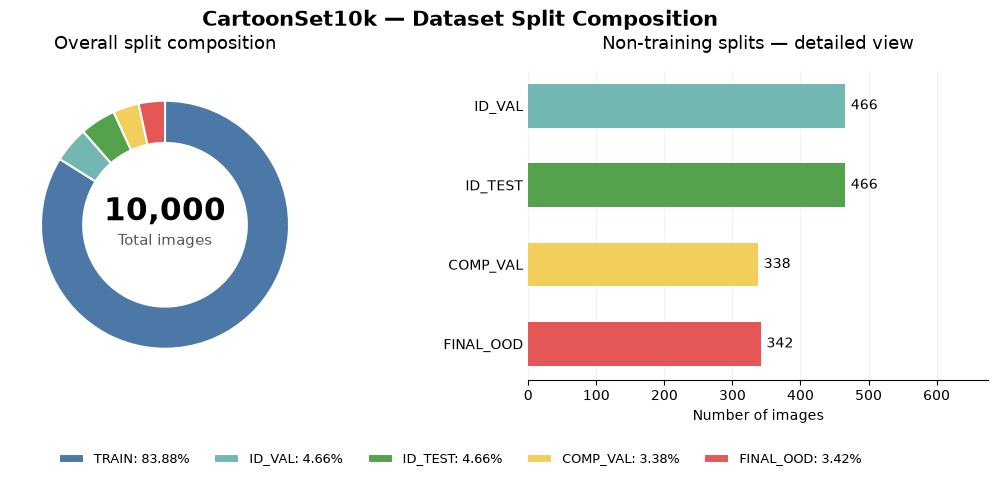

In [27]:

import json
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# --- Load frozen dataset metadata ---
summary = json.loads(
    (DATA / "split_summary.json").read_text(encoding="utf-8")
)

dataset_summary = summary["datasets"][VARIANT]
counts = dataset_summary["final_split_counts"]
integrity = dataset_summary["integrity_assertions"]

roles = ["TRAIN", "ID_VAL", "ID_TEST", "COMP_VAL", "FINAL_OOD"]

assert integrity["all_assertions_passed"]
assert integrity["partition_pairwise_disjoint"]
assert integrity["partition_union_equals_source"]
assert integrity["heldout_pairs_absent_from_train"]
assert integrity["exact_image_hashes_crossing_roles"] == 0

values = [counts[role] for role in roles]
total = sum(values)

# --- Display exact split counts ---
display(Markdown(
    "| Dataset role | Images | Share |\n"
    "|---|---:|---:|\n" +
    "\n".join(
        f"| {role} | {counts[role]:,} | "
        f"{counts[role] / total * 100:.2f}% |"
        for role in roles
    )
))

display(Markdown(
    f"**Integrity checks:** all passed; "
    f"disjoint partitions = `{integrity['partition_pairwise_disjoint']}`; "
    f"union equals source = `{integrity['partition_union_equals_source']}`; "
    f"held-out pairs absent from TRAIN = "
    f"`{integrity['heldout_pairs_absent_from_train']}`; "
    f"cross-role duplicate image hashes = "
    f"`{integrity['exact_image_hashes_crossing_roles']}`."
))

# --- Publication-ready visualization ---
FIGURE_DIR = ROOT / "docs" / "report" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

colors = {
    "TRAIN": "#4C78A8",
    "ID_VAL": "#72B7B2",
    "ID_TEST": "#54A24B",
    "COMP_VAL": "#F2CF5B",
    "FINAL_OOD": "#E45756",
}

fig, (ax_donut, ax_detail) = plt.subplots(
    1, 2,
    figsize=(11, 5),
    gridspec_kw={"width_ratios": [1, 1.15]},
)

# Panel A: full dataset donut
wedges, _ = ax_donut.pie(
    values,
    colors=[colors[r] for r in roles],
    startangle=90,
    counterclock=False,
    wedgeprops={
        "width": 0.34,
        "edgecolor": "white",
        "linewidth": 1.5,
    },
)

ax_donut.text(
    0, 0.10,
    f"{total:,}",
    ha="center",
    va="center",
    fontsize=22,
    fontweight="bold",
)

ax_donut.text(
    0, -0.13,
    "Total images",
    ha="center",
    va="center",
    fontsize=11,
    color="#555555",
)

ax_donut.set_title(
    "Overall split composition",
    fontsize=13,
    pad=15,
)
ax_donut.set_aspect("equal")

# Panel B: zoom into non-training roles
detail_roles = roles[1:]
detail_values = [counts[r] for r in detail_roles]

bars = ax_detail.barh(
    detail_roles,
    detail_values,
    color=[colors[r] for r in detail_roles],
    height=0.55,
)

ax_detail.invert_yaxis()
ax_detail.set_xlim(0, max(detail_values) * 1.45)
ax_detail.set_xlabel("Number of images", fontsize=10)
ax_detail.set_title(
    "Non-training splits — detailed view",
    fontsize=13,
    pad=15,
)

for bar, role in zip(bars, detail_roles):
    value = counts[role]

    ax_detail.text(
        value + 8,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,}",
        va="center",
        ha="left",
        fontsize=10,
    )

ax_detail.grid(
    axis="x",
    alpha=0.16,
    linewidth=0.8,
)
ax_detail.set_axisbelow(True)
ax_detail.spines["top"].set_visible(False)
ax_detail.spines["right"].set_visible(False)
ax_detail.spines["left"].set_visible(False)
ax_detail.tick_params(axis="y", length=0)

# Main title and shared legend
fig.suptitle(
    "CartoonSet10k — Dataset Split Composition",
    fontsize=15,
    fontweight="semibold",
    y=0.97,
)

legend_labels = [
    f"{role}: {counts[role] / total * 100:.2f}%"
    for role in roles
]

fig.legend(
    wedges,
    legend_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.035),
    ncol=5,
    frameon=False,
    fontsize=9,
)

fig.subplots_adjust(
    left=0.05,
    right=0.98,
    top=0.85,
    bottom=0.23,
    wspace=0.38,
)

# Export in raster and vector formats
for suffix in ("png", "pdf"):
    fig.savefig(
        FIGURE_DIR / f"dataset_split_composition.{suffix}",
        dpi=300 if suffix == "png" else None,
        bbox_inches="tight",
        pad_inches=0.15,
    )

plt.show()


## 4. Controlled compositional OOD construction

OOD1–OOD4 hold out one *pair* of attribute values at a time. The primitive values remain represented in TRAIN with other partners, so this tests composition rather than recognition of unseen individual attributes. The four definitions below are read directly from `heldout_combinations.json`; no protected per-image assignment is exposed.

- **OOD1**: `face_shape=oval` + `glasses=rimless_glasses`
- **OOD2**: `face_shape=round` + `hair_color=dark_brown`
- **OOD3**: `glasses=heart_glasses` + `face_color=pale_pink`
- **OOD4**: `hair_color=light_blond` + `face_color=deep_brown`

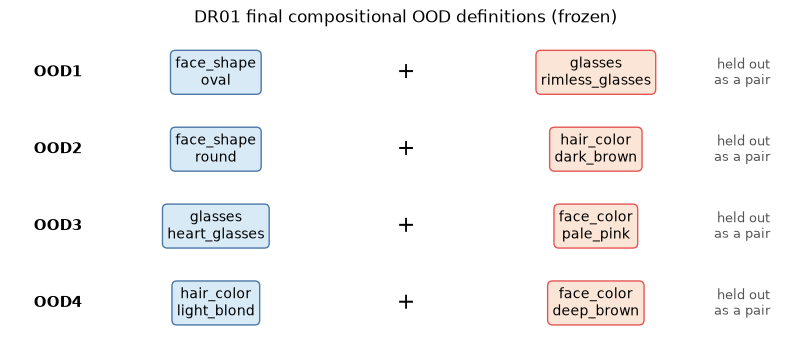

In [28]:
heldout = json.loads((DATA / 'heldout_combinations.json').read_text(encoding='utf-8'))
ood_rows = heldout['final_ood_definitions']
assert [row['name'] for row in ood_rows] == ['OOD1', 'OOD2', 'OOD3', 'OOD4']
mapping_payload = json.loads((DATA / 'semantic_mapping.json').read_text(encoding='utf-8'))
mapping = mapping_payload['attributes']

def semantic_name(attribute, value):
    values = mapping[attribute]
    if isinstance(values, dict):
        return values[str(value)]
    return next(item['canonical_label'] for item in values if item['raw_id'] == value)

lines = []
for row in ood_rows:
    left = f"{row['attribute_a']}={semantic_name(row['attribute_a'], row['value_a'])}"
    right = f"{row['attribute_b']}={semantic_name(row['attribute_b'], row['value_b'])}"
    lines.append(f"- **{row['name']}**: `{left}` + `{right}`")
display(Markdown('\n'.join(lines)))

fig, ax = plt.subplots(figsize=(8.0, 3.5), constrained_layout=True)
ax.axis('off')
for i, row in enumerate(ood_rows):
    y = 0.87 - i * 0.24
    left = f"{row['attribute_a']}\n{semantic_name(row['attribute_a'], row['value_a'])}"
    right = f"{row['attribute_b']}\n{semantic_name(row['attribute_b'], row['value_b'])}"
    ax.text(0.03, y, row['name'], weight='bold', va='center', fontsize=11)
    ax.text(0.26, y, left, ha='center', va='center', bbox={'boxstyle': 'round,pad=0.35', 'facecolor': '#D9EAF7', 'edgecolor': '#4C78A8'})
    ax.text(0.50, y, '+', ha='center', va='center', fontsize=16)
    ax.text(0.74, y, right, ha='center', va='center', bbox={'boxstyle': 'round,pad=0.35', 'facecolor': '#FBE5D6', 'edgecolor': '#E45756'})
    ax.text(0.96, y, 'held out\nas a pair', ha='right', va='center', fontsize=9, color='#555555')
ax.set_title('DR01 final compositional OOD definitions (frozen)')
for suffix in ('png', 'pdf'):
    fig.savefig(FIGURE_DIR / f'compositional_ood_holdout.{suffix}', dpi=220 if suffix == 'png' else None, bbox_inches='tight')
plt.show()


## 5. Interpretation, integrity, and limitations

The frozen integrity assertions establish role-level disjointness and absence of each final held-out pair from TRAIN. They do not establish that a generated image has correctly realised every requested attribute: that is an evaluation question handled by the separately versioned evaluator protocols. Likewise, native-32 and native-64 outcomes must be interpreted under their own input views and protocols. This notebook documents data construction and conditioning contracts; it does not run training, sampling, or a new benchmark.

**Provenance.** Split definitions: `data/processed/dr01_v1/heldout_combinations.json`; aggregate assertions: `data/processed/dr01_v1/split_summary.json`; semantic values: `data/processed/dr01_v1/semantic_mapping.json`; caption/tokenisation implementation: `src/tiny_avatar_diffusion/captions.py` and `src/tiny_avatar_diffusion/tokenizer.py`.